# Ensemble: XGBoost + Isolation Forest

Heterogeneous ensemble of a supervised detector (XGBoost) and an unsupervised one (Isolation Forest), fused per hour.

**Inputs** (all already in the repo)
- XGBoost per-hour scores: `models/XGBoost/notebook_outputs/seed*/xgb_hourly_scores.csv` (from `XGBoost_BATADAL.ipynb`; Dataset 2 hours are out-of-fold).
- Isolation Forest: the team's scores in `models/Isolation_Forest/iforest_ensemble_outputs.zip` (36 raw sensors, 200 trees; read as CSV, the `.joblib` models are not loaded). For comparison, the paper's recipe (sensors + 1-step differences, 20 PCA components, 500 trees; `isolation_forest.py`) is refitted here on Dataset 1 train.

**Rules.** Scores are put on a common scale with the calibration block only; fusion is a fixed rule (`mean`, the paper's 0.4/0.1 `paper` weights, or `max`), never fitted on Dataset 2; the alarm threshold is the lowest one within the budget (<= 1 episode/week, <= 1% of hours) on the calibration block. Positives are `ATT_FLAG = 1` hours (`-999` dropped); false alarms are counted on the validation block, reported as alarm hours per clean week. **No precision or F1** (true positives come from Dataset 2, false positives from the validation block, so they only reflect the mix; compute them on the Test set), and the S-score is the *approximate* one. Episodes merge alarms at most 3 quiet hours apart for every detector. `d2_clean_alarm_fraction` is the era check: the share of Dataset 2 hours outside every attack window that alarm (budget 1%). `*_schedule` columns use every hour of a real attack window as positive. The proposal's fusion rule is `max` of calibration percentiles, so that is the headline; the others are shown for completeness. Run from `models/Ensemble/`.

In [1]:
import sys, pathlib, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve
sys.path.insert(0, '.'); sys.path.insert(0, '../XGBoost')
import ensemble as E
from isolation_forest import fit_scores
from xgb_data import load_blocks
pd.set_option('display.width', 220)

XGB_DIR = pathlib.Path('../XGBoost/notebook_outputs')
TEAM_ZIP = pathlib.Path('../Isolation_Forest/iforest_ensemble_outputs.zip')
DATA_DIR = pathlib.Path('../../data/processed')
OUT_DIR = pathlib.Path('notebook_outputs'); OUT_DIR.mkdir(exist_ok=True)
SEEDS = [0, 1, 2]

## 1. Load the scores

XGBoost seed k is paired with Isolation Forest seed k; hours are matched by `DATETIME` (team) or by row (ours).

In [2]:
blocks = load_blocks(str(DATA_DIR), time_features=False)

def own_pca_iforest(seed):
    scores, explained, n_cols = fit_scores(blocks, seed)
    frames = []
    for source, name in (('val', 'val'), ('cal', 'cal'), ('d2', 'd2')):
        frames.append(pd.DataFrame({'source': source, 'row': blocks[name][1]['row'].to_numpy(), 'if_score': scores[name]}))
    return pd.concat(frames, ignore_index=True)

forests = {'team': {s: E.read_teammate_iforest(TEAM_ZIP, s) for s in SEEDS},
           'own_pca': {s: own_pca_iforest(s) for s in SEEDS}}
frames = {(v, s): E.load_scores(XGB_DIR / f'seed{s}' / 'xgb_hourly_scores.csv', forests[v][s])
          for v in forests for s in SEEDS}
f = frames[('team', 0)]
print(f.groupby('source').size().to_dict(), '| labeled attack hours:', int((f.att_flag == 1).sum()),
      '| attack-window hours:', int((f.attack_id > 0).sum()))

{'cal': 1706, 'd2': 4154, 'val': 1705} | labeled attack hours: 219 | attack-window hours: 492


## 2. Every single detector and every fusion, 3 seeds

In [3]:
rows = []
for (variant, seed), frame in frames.items():
    for norm in ('percentile', 'ratio'):
        for r in E.run(frame, None, norm):
            rows.append({'iforest': variant, 'seed': seed, **r})
all_runs = pd.DataFrame(rows)
all_runs.to_csv(OUT_DIR / 'all_runs.csv', index=False)
metrics = ['detected', 'mean_delay', 'recall', 'tnr', 'val_alarm_hours_per_week', 'd2_clean_alarm_fraction', 'recall_schedule', 'roc_auc', 'pr_auc', 'roc_auc_schedule', 's_score_approx']
summary = all_runs.groupby(['iforest', 'norm', 'detectors', 'fusion'], sort=False)[metrics].mean().round(3)
summary.to_csv(OUT_DIR / 'summary.csv')
summary.loc['team'].loc['percentile']

detected  mean_delay  recall    tnr  val_alarm_hours_per_week  d2_clean_alarm_fraction  recall_schedule  roc_auc  pr_auc  roc_auc_schedule  s_score_approx
detectors   fusion                                                                                                                                                            
xgb         single     4.333      17.533   0.248  0.995                     0.920                    0.015            0.259    0.692   0.480             0.748           0.542
iforest     single     5.333      34.889   0.052  0.994                     1.084                    0.009            0.027    0.729   0.292             0.651           0.463
xgb+iforest mean       4.000      19.167   0.050  0.996                     0.755                    0.008            0.054    0.751   0.292             0.736           0.446
            paper      4.333      15.167   0.093  0.995                     0.821                    0.009            0.096    0.717   0.343             0.751           0.500
            max        6.333      24.016   0.259  0.993                     1.215                    0.016            0.255    0.875   0.584             0.824           0.626

In [4]:
summary.loc['own_pca'].loc['percentile']

detected  mean_delay  recall    tnr  val_alarm_hours_per_week  d2_clean_alarm_fraction  recall_schedule  roc_auc  pr_auc  roc_auc_schedule  s_score_approx
detectors   fusion                                                                                                                                                            
xgb         single     4.333      17.533   0.248  0.995                     0.920                    0.015            0.259    0.692   0.480             0.748           0.542
iforest     single     6.000      12.111   0.482  0.993                     1.215                    0.010            0.295    0.802   0.624             0.673           0.744
xgb+iforest mean       7.000      22.762   0.104  0.993                     1.248                    0.010            0.110    0.805   0.384             0.755           0.620
            paper      6.000      24.222   0.119  0.993                     1.117                    0.010            0.126    0.735   0.398             0.759           0.587
            max        7.000      20.571   0.693  0.995                     0.821                    0.017            0.492    0.949   0.866             0.864           0.799

In [5]:
summary.loc['team'].loc['ratio']

detected  mean_delay  recall    tnr  val_alarm_hours_per_week  d2_clean_alarm_fraction  recall_schedule  roc_auc  pr_auc  roc_auc_schedule  s_score_approx
detectors   fusion                                                                                                                                                            
xgb         single     4.667      17.500   0.253  0.994                     1.018                    0.015            0.264    0.692   0.483             0.748           0.564
iforest     single     5.333      34.889   0.053  0.994                     1.084                    0.009            0.028    0.729   0.294             0.651           0.464
xgb+iforest mean       4.667      17.500   0.251  0.994                     1.018                    0.015            0.262    0.870   0.560             0.817           0.564
            paper      4.667      17.500   0.253  0.994                     1.018                    0.015            0.263    0.813   0.518             0.804           0.564
            max        4.667      17.500   0.253  0.994                     1.051                    0.015            0.264    0.824   0.536             0.743           0.564

## 3. Headline: `max` of calibration percentiles

The fusion rule given in the project proposal, per seed, for both Isolation Forests.

In [6]:
head = all_runs[(all_runs.norm == 'percentile') & (all_runs.fusion == 'max')]
head[['iforest', 'seed'] + metrics]

,iforest,seed,detected,mean_delay,recall,tnr,val_alarm_hours_per_week,d2_clean_alarm_fraction,recall_schedule,roc_auc,pr_auc,roc_auc_schedule,s_score_approx
4,team,0,7,20.714286,0.273973,0.991789,1.379472,0.017477,0.256098,0.877173,0.599818,0.826395,0.673656
14,team,1,6,24.000000,0.260274,0.993548,1.083871,0.016931,0.260163,0.877986,0.587625,0.822832,0.616720
24,team,2,6,27.333333,0.242009,0.992962,1.182405,0.015019,0.247967,0.869112,0.565891,0.822902,0.588197
34,own_pca,0,7,14.285714,0.694064,0.994135,0.985337,0.018023,0.489837,0.951213,0.874957,0.867204,0.831038
44,own_pca,1,7,22.285714,0.698630,0.995308,0.788270,0.017750,0.497967,0.948330,0.865011,0.861387,0.796109
54,own_pca,2,7,25.142857,0.684932,0.995894,0.689736,0.015565,0.487805,0.947902,0.858368,0.863903,0.769022


In [7]:
comp = all_runs[(all_runs.norm == 'percentile') & (all_runs.fusion.isin(['single', 'max']))]
comp = comp.assign(detector=comp.detectors.replace({'xgb': 'XGBoost', 'iforest': 'Isolation Forest', 'xgb+iforest': 'Ensemble (max)'}))
out = comp.groupby(['iforest', 'detector'], sort=False)[metrics].mean().round(3)
out.to_csv(OUT_DIR / 'headline.csv'); out

detected  mean_delay  recall    tnr  val_alarm_hours_per_week  d2_clean_alarm_fraction  recall_schedule  roc_auc  pr_auc  roc_auc_schedule  s_score_approx
iforest detector                                                                                                                                                                    
team    XGBoost              4.333      17.533   0.248  0.995                     0.920                    0.015            0.259    0.692   0.480             0.748           0.542
        Isolation Forest     5.333      34.889   0.052  0.994                     1.084                    0.009            0.027    0.729   0.292             0.651           0.463
        Ensemble (max)       6.333      24.016   0.259  0.993                     1.215                    0.016            0.255    0.875   0.584             0.824           0.626
own_pca XGBoost              4.333      17.533   0.248  0.995                     0.920                    0.015            0.259    0.692   0.480             0.748           0.542
        Isolation Forest     6.000      12.111   0.482  0.993                     1.215                    0.010            0.295    0.802   0.624             0.673           0.744
        Ensemble (max)       7.000      20.571   0.693  0.995                     0.821                    0.017            0.492    0.949   0.866             0.864           0.799

## 4. Per-attack detail (seed 0, max of percentiles)

In [8]:
def fused(frame, how='max', norm='percentile'):
    scaled = pd.DataFrame({'xgb': E.normalise(frame, 'xgb_score', norm), 'iforest': E.normalise(frame, 'if_score', norm)})
    view = frame[['source', 'row', 'att_flag', 'attack_id']].copy()
    view['score'] = scaled.max(axis=1).to_numpy() if how == 'max' else scaled.mean(axis=1).to_numpy()
    view['xgb_p'], view['if_p'] = scaled['xgb'].to_numpy(), scaled['iforest'].to_numpy()
    return view

detail = {}
for variant in forests:
    view = fused(frames[(variant, 0)])
    m, per = E.evaluate(view, 'score')
    detail[variant] = (view, m, pd.DataFrame(per))
    print(variant, '| threshold', round(m['threshold'], 4), '| detected', m['detected'], '/', m['attacks'],
          '| recall', round(m['recall'], 3), '| TNR', round(m['tnr'], 4), '| val episodes/week', round(m['val_episodes_per_week'], 2))
detail['team'][2].merge(detail['own_pca'][2], on='attack', suffixes=('_teamIF', '_ownIF'))

team | threshold 0.9959 | detected 7 / 7 | recall 0.274 | TNR 0.9918 | val episodes/week 1.08
own_pca | threshold 0.9959 | detected 7 / 7 | recall 0.694 | TNR 0.9941 | val episodes/week 0.89


,attack,detected_teamIF,delay_teamIF,labeled_teamIF,labeled_alarmed_teamIF,window_hours_teamIF,window_alarmed_teamIF,detected_ownIF,delay_ownIF,labeled_ownIF,labeled_alarmed_ownIF,window_hours_ownIF,window_alarmed_ownIF
0,1,True,25,42,1,50,1,True,0,42,32,50,38
1,2,True,3,0,0,24,16,True,3,0,0,24,16
2,3,True,25,60,17,60,17,True,25,60,17,60,17
3,4,True,10,37,36,94,72,True,10,37,36,94,73
4,5,True,8,7,0,60,13,True,6,7,0,60,18
5,6,True,29,73,6,94,6,True,11,73,67,94,75
6,7,True,45,0,0,110,1,True,45,0,0,110,4


## 5. Which detector fires on which hours?

Share of the 219 labeled attack hours alarmed by each member and by the ensemble (seed 0, team Isolation Forest).

In [9]:
view, m, _ = detail['team']
thr_member = {}
for col, name in (('xgb_p', 'XGBoost'), ('if_p', 'Isolation Forest'), ('score', 'Ensemble (max)')):
    thr = E.find_threshold(view.loc[view.source == 'cal', col].to_numpy(), 0.01, 1.0)
    pos = view[(view.source == 'd2') & (view.att_flag == 1)]
    thr_member[name] = (pos[col] > thr).mean().round(3)
bothk = view[(view.source == 'd2') & (view.att_flag == 1)]
xt = E.find_threshold(view.loc[view.source == 'cal', 'xgb_p'].to_numpy(), 0.01, 1.0)
it = E.find_threshold(view.loc[view.source == 'cal', 'if_p'].to_numpy(), 0.01, 1.0)
print('recall on labeled hours:', thr_member)
print('only XGBoost:', int(((bothk.xgb_p > xt) & ~(bothk.if_p > it)).sum()), '| only Isolation Forest:', int((~(bothk.xgb_p > xt) & (bothk.if_p > it)).sum()),
      '| both:', int(((bothk.xgb_p > xt) & (bothk.if_p > it)).sum()), '| neither:', int((~(bothk.xgb_p > xt) & ~(bothk.if_p > it)).sum()))

recall on labeled hours: {'XGBoost': np.float64(0.247), 'Isolation Forest': np.float64(0.059), 'Ensemble (max)': np.float64(0.274)}
only XGBoost: 49 | only Isolation Forest: 8 | both: 5 | neither: 157


## 6. ROC and precision-recall curves (seed 0)

Labeled attack hours (out-of-fold) against the validation block.

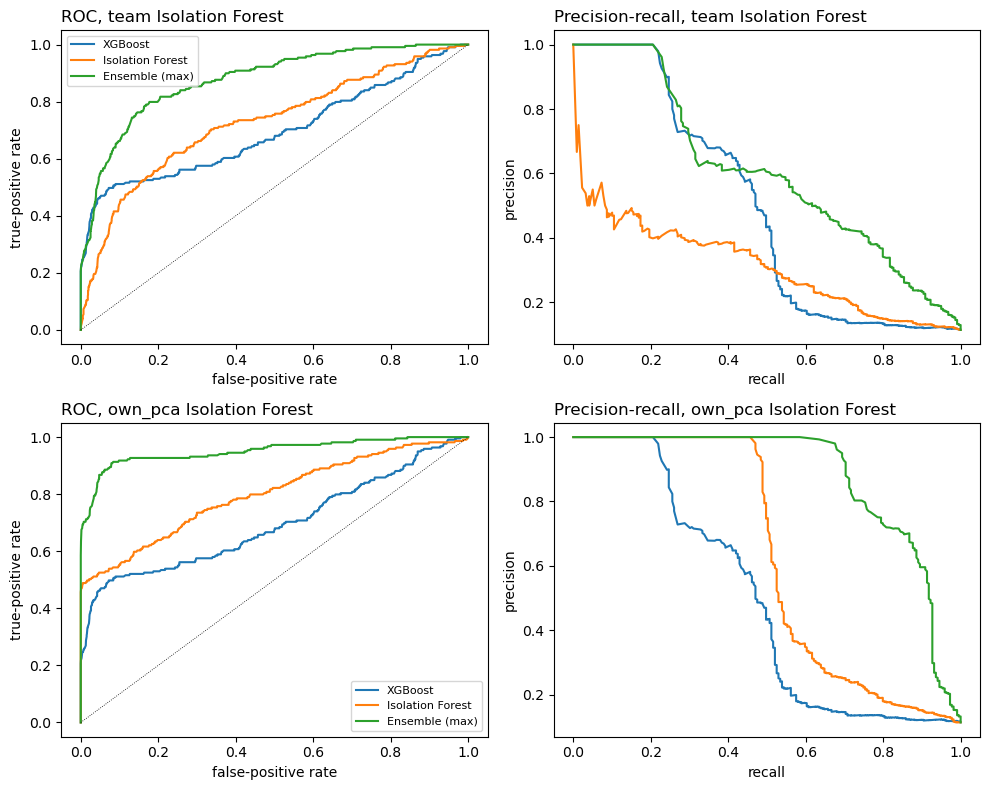

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, variant in enumerate(('team', 'own_pca')):
    view = detail[variant][0]
    pos = view[(view.source == 'd2') & (view.att_flag == 1)]; neg = view[view.source == 'val']
    y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
    for col, name in (('xgb_p', 'XGBoost'), ('if_p', 'Isolation Forest'), ('score', 'Ensemble (max)')):
        s = np.r_[pos[col], neg[col]]
        fpr, tpr, _ = roc_curve(y, s); p, r, _ = precision_recall_curve(y, s)
        axes[row, 0].plot(fpr, tpr, label=name); axes[row, 1].plot(r, p, label=name)
    axes[row, 0].plot([0, 1], [0, 1], 'k:', lw=0.6)
    axes[row, 0].set_title(f'ROC, {variant} Isolation Forest', loc='left'); axes[row, 1].set_title(f'Precision-recall, {variant} Isolation Forest', loc='left')
    axes[row, 0].set_xlabel('false-positive rate'); axes[row, 0].set_ylabel('true-positive rate')
    axes[row, 1].set_xlabel('recall'); axes[row, 1].set_ylabel('precision'); axes[row, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / 'roc_pr_curves.png', dpi=150)

## 7. Attack windows: ensemble score against the alarm threshold (seed 0)

Shaded = labeled hours (`ATT_FLAG = 1`); the other hours in each window are the unlabeled (`-999`) ones, used only to time the first alarm.

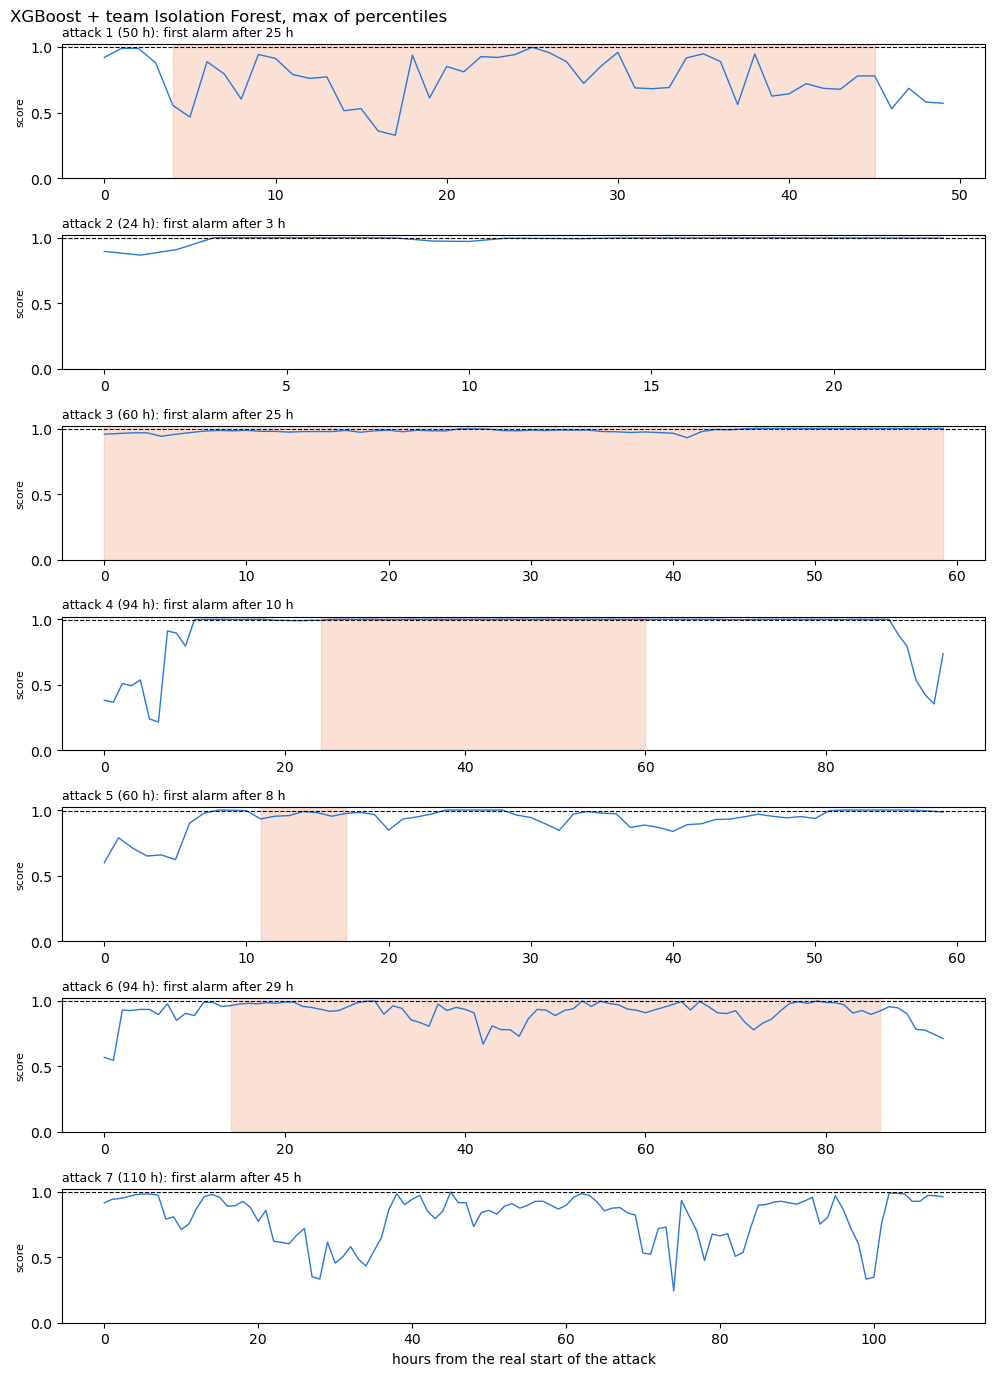

In [11]:
def plot_windows(variant):
    view, m, per = detail[variant]
    d2 = view[view.source == 'd2']
    fig, axes = plt.subplots(7, 1, figsize=(10, 14))
    for ax, a in zip(axes, range(1, 8)):
        part = d2[d2.attack_id == a].sort_values('row')
        h = np.arange(len(part))
        ax.plot(h, part.score.to_numpy(), lw=1, color='#2a78d6')
        ax.axhline(m['threshold'], color='k', ls='--', lw=0.8)
        ax.fill_between(h, 0, 1, where=(part.att_flag == 1).to_numpy(), color='#eb6834', alpha=0.2, transform=ax.get_xaxis_transform())
        r = per[per.attack == a].iloc[0]
        ax.set_title(f"attack {a} ({len(part)} h): " + (f"first alarm after {int(r.delay)} h" if r.detected else 'MISSED'), loc='left', fontsize=9)
        ax.set_ylim(0, 1.02); ax.set_ylabel('score', fontsize=8)
    axes[-1].set_xlabel('hours from the real start of the attack')
    fig.suptitle(f'XGBoost + {variant} Isolation Forest, max of percentiles', x=0.01, ha='left'); plt.tight_layout()
    plt.savefig(OUT_DIR / f'attack_windows_{variant}.png', dpi=130)
plot_windows('team')

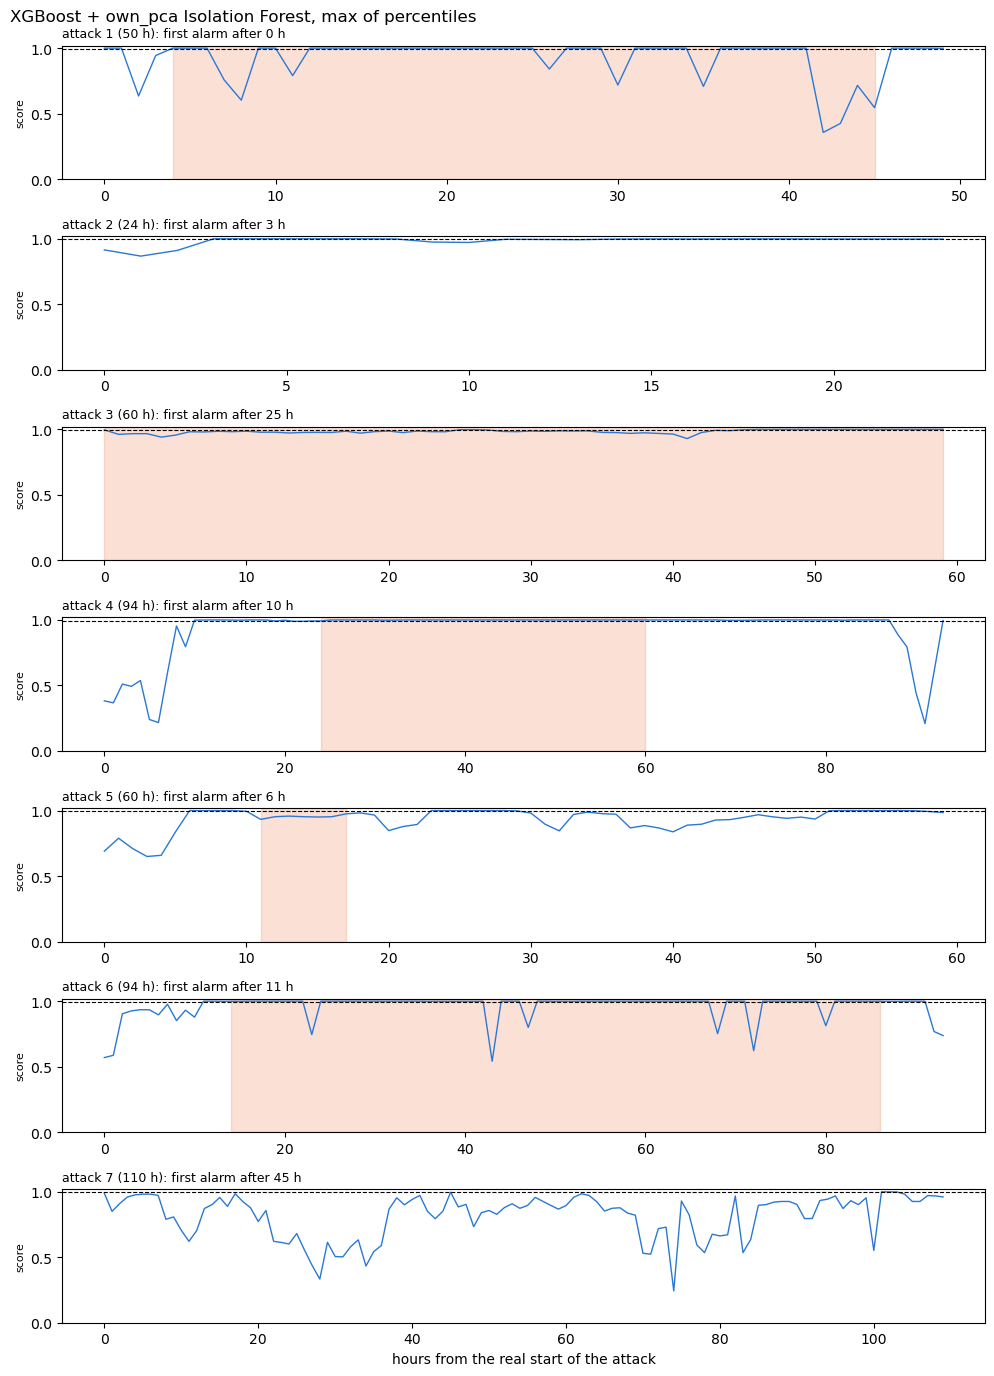

In [12]:
plot_windows('own_pca')

## 8. Clean-data behaviour

False alarms on the validation block at the calibration threshold, and how the clean-hour scores compare with the threshold.

In [13]:
rows = []
for variant in forests:
    for seed in SEEDS:
        view = fused(frames[(variant, seed)])
        m, _ = E.evaluate(view, 'score')
        rows.append({'iforest': variant, 'seed': seed, 'threshold': round(m['threshold'], 4),
                     'calibration alarm fraction': round(m['cal_alarm_fraction'], 4), 'validation TNR': round(m['tnr'], 4), 'validation alarm h/week': round(m['val_alarm_hours_per_week'], 2), 'Dataset 2 clean-hour alarm fraction': round(m['d2_clean_alarm_fraction'], 4),
                     'validation episodes/week': round(m['val_episodes_per_week'], 2)})
pd.DataFrame(rows)

,iforest,seed,threshold,calibration alarm fraction,validation TNR,validation alarm h/week,Dataset 2 clean-hour alarm fraction,validation episodes/week
0,team,0,0.9959,0.0082,0.9918,1.38,0.0175,1.08
1,team,1,0.9965,0.0070,0.9935,1.08,0.0169,0.89
2,team,2,0.9965,0.0070,0.9930,1.18,0.0150,0.89
3,own_pca,0,0.9959,0.0082,0.9941,0.99,0.0180,0.89
4,own_pca,1,0.9965,0.0070,0.9953,0.79,0.0177,0.69
5,own_pca,2,0.9965,0.0070,0.9959,0.69,0.0156,0.59


## 9. Reading the results

See `models/Ensemble/ensemble_approach.md` for the discussion. The tables above are the numbers; `notebook_outputs/` holds `all_runs.csv`, `summary.csv`, `headline.csv` and the plots.